Settings

In [1]:
from pathlib import Path

import torch
import deepinv as dinv
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [2]:
device = "cpu"

image_size = 32
batch_size = 8

project_root = Path("..") if Path.cwd().name == "notebooks" else Path(".")
data_dir = project_root / "data"
output_dir = project_root / "outputs"

data_dir.mkdir(exist_ok=True)
output_dir.mkdir(exist_ok=True)

print("Device:", device)
print("Data directory:", data_dir)
print("Output directory:", output_dir)

Device: cpu
Data directory: ..\data
Output directory: ..\outputs


In [3]:
transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
])

dataset = datasets.MNIST(
    root=data_dir,
    train=True,
    download=True,
    transform=transform,
)

loader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
)

x, labels = next(iter(loader))
x = x.to(device)

print("Image batch shape:", x.shape)
print("Labels:", labels)

100%|██████████| 9.91M/9.91M [00:01<00:00, 6.25MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 156kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 1.77MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.44MB/s]


Image batch shape: torch.Size([8, 1, 32, 32])
Labels: tensor([6, 9, 3, 0, 7, 5, 4, 9])


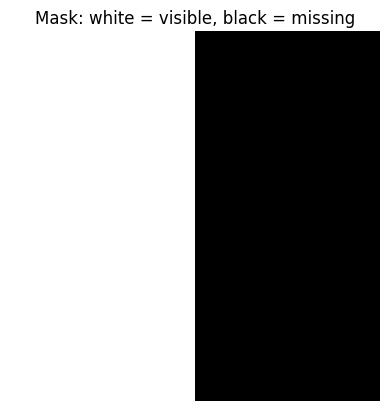

In [4]:
mask = torch.ones(1, image_size, image_size, device=device)

# Remove right half
mask[:, :, image_size // 2:] = 0

plt.imshow(mask[0].cpu(), cmap="gray")
plt.title("Mask: white = visible, black = missing")
plt.axis("off")
plt.show()

In [5]:
physics = dinv.physics.Inpainting(
    mask=mask,
    img_size=(1, image_size, image_size),
    device=device,
)

y = physics(x)

print("Original shape:", x.shape)
print("Measurement/masked shape:", y.shape)

Original shape: torch.Size([8, 1, 32, 32])
Measurement/masked shape: torch.Size([8, 1, 32, 32])


In [ ]:
x_baseline = physics.A_adjoint(y)

print("Baseline reconstruction shape:", x_baseline.shape)

Baseline reconstruction shape: torch.Size([8, 1, 32, 32])


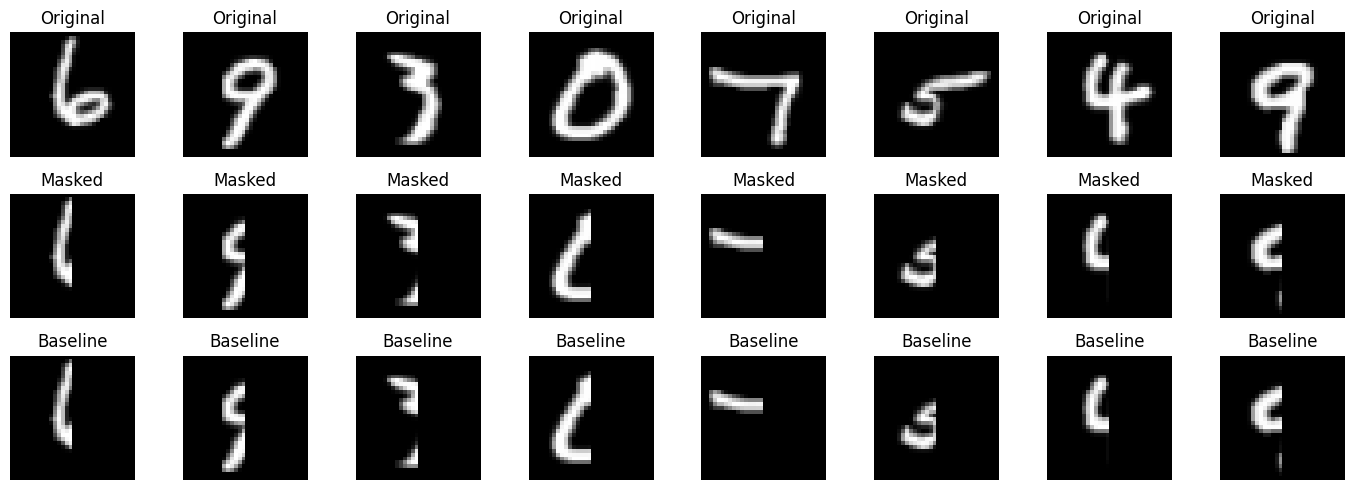

In [ ]:
num_images = 8

fig, axes = plt.subplots(3, num_images, figsize=(14, 5))

for i in range(num_images):
    axes[0, i].imshow(x[i, 0].detach().cpu(), cmap="gray")
    axes[0, i].axis("off")
    axes[0, i].set_title("Original")

    axes[1, i].imshow(y[i, 0].detach().cpu(), cmap="gray")
    axes[1, i].axis("off")
    axes[1, i].set_title("Masked")

    axes[2, i].imshow(x_baseline[i, 0].detach().cpu(), cmap="gray")
    axes[2, i].axis("off")
    axes[2, i].set_title("Baseline")

plt.tight_layout()
plt.show()

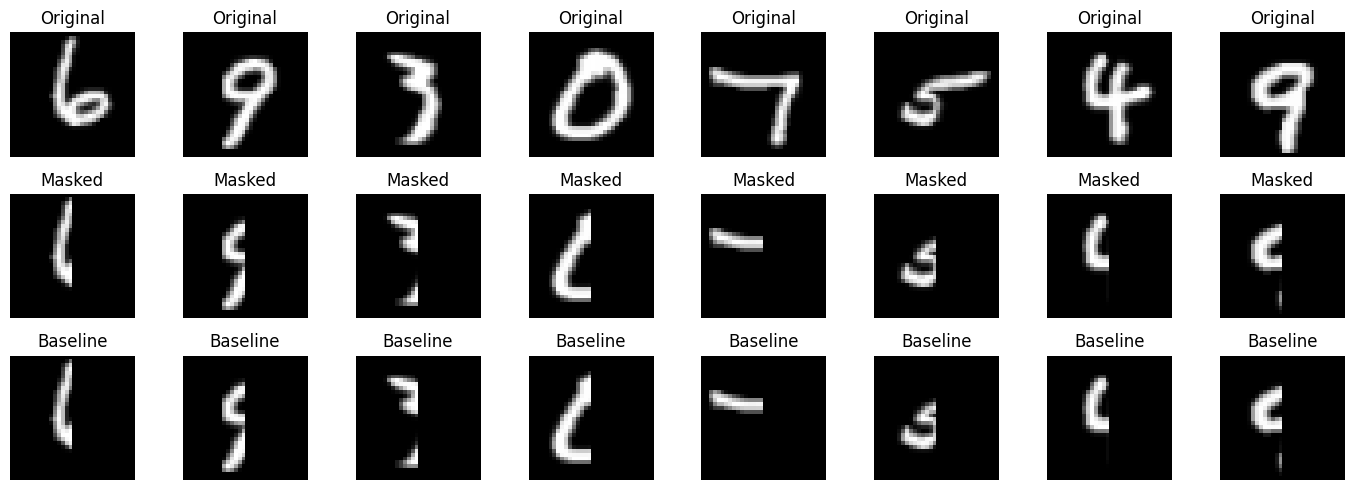

Saved result to: ..\outputs\deepinverse_mnist_inpainting_baseline.png


In [8]:
save_path = output_dir / "deepinverse_mnist_inpainting_baseline.png"

fig, axes = plt.subplots(3, num_images, figsize=(14, 5))

for i in range(num_images):
    axes[0, i].imshow(x[i, 0].detach().cpu(), cmap="gray")
    axes[0, i].axis("off")
    axes[0, i].set_title("Original")

    axes[1, i].imshow(y[i, 0].detach().cpu(), cmap="gray")
    axes[1, i].axis("off")
    axes[1, i].set_title("Masked")

    axes[2, i].imshow(x_baseline[i, 0].detach().cpu(), cmap="gray")
    axes[2, i].axis("off")
    axes[2, i].set_title("Baseline")

plt.tight_layout()
plt.savefig(save_path, dpi=200)
plt.show()

print("Saved result to:", save_path)

In [9]:
mse = torch.mean((x - x_baseline) ** 2).item()

print("MSE between original and baseline reconstruction:", mse)

MSE between original and baseline reconstruction: 0.0566863976418972


In [10]:
import torch.nn as nn
import torch.nn.functional as F


class SimpleInpaintingCNN(nn.Module):
    def __init__(self):
        super().__init__()
        
        # input channels = 2:
        # channel 1: masked image
        # channel 2: mask
        self.net = nn.Sequential(
            nn.Conv2d(2, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Sigmoid(),  # output in [0, 1], like MNIST images
        )
        
    def forward(self, masked_img, mask):
        # mask shape: [1, 32, 32] or [B, 1, 32, 32]
        if mask.dim() == 3:
            mask = mask.unsqueeze(0)
        
        mask_batch = mask.expand(masked_img.shape[0], -1, -1, -1)
        
        model_input = torch.cat([masked_img, mask_batch], dim=1)
        predicted_full_image = self.net(model_input)
        
        # Keep known pixels from the measurement.
        # Use model prediction only for missing pixels.
        reconstruction = masked_img * mask_batch + predicted_full_image * (1 - mask_batch)
        
        return reconstruction

In [11]:
model = SimpleInpaintingCNN().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

print(model)

SimpleInpaintingCNN(
  (net): Sequential(
    (0): Conv2d(2, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): Sigmoid()
  )
)


In [12]:
from tqdm.notebook import tqdm

epochs = 3

train_losses = []

for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0
    
    for clean_imgs, _ in tqdm(loader, desc=f"Epoch {epoch+1}/{epochs}"):
        clean_imgs = clean_imgs.to(device)
        
        # Apply DeepInverse inpainting physics
        masked_imgs = physics(clean_imgs)
        
        # Reconstruct
        reconstructed_imgs = model(masked_imgs, mask)
        
        # Compare reconstruction with original clean image
        loss = criterion(reconstructed_imgs, clean_imgs)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
    
    avg_loss = epoch_loss / len(loader)
    train_losses.append(avg_loss)
    
    print(f"Epoch {epoch+1}/{epochs} - Loss: {avg_loss:.6f}")

Epoch 1/3:   0%|          | 0/7500 [00:00<?, ?it/s]

Epoch 1/3 - Loss: 0.024503


Epoch 2/3:   0%|          | 0/7500 [00:00<?, ?it/s]

Epoch 2/3 - Loss: 0.022532


Epoch 3/3:   0%|          | 0/7500 [00:00<?, ?it/s]

Epoch 3/3 - Loss: 0.022049


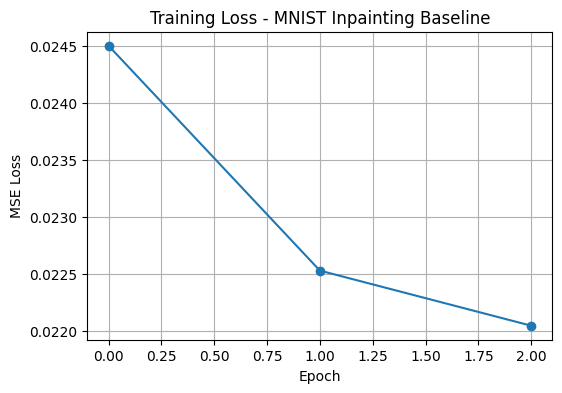

In [13]:
plt.figure(figsize=(6, 4))
plt.plot(train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss - MNIST Inpainting Baseline")
plt.grid(True)
plt.show()

In [14]:
model.eval()

with torch.no_grad():
    x_test, labels_test = next(iter(loader))
    x_test = x_test.to(device)
    
    y_test = physics(x_test)
    x_reconstructed = model(y_test, mask)

print("Original:", x_test.shape)
print("Masked:", y_test.shape)
print("Reconstructed:", x_reconstructed.shape)

Original: torch.Size([8, 1, 32, 32])
Masked: torch.Size([8, 1, 32, 32])
Reconstructed: torch.Size([8, 1, 32, 32])


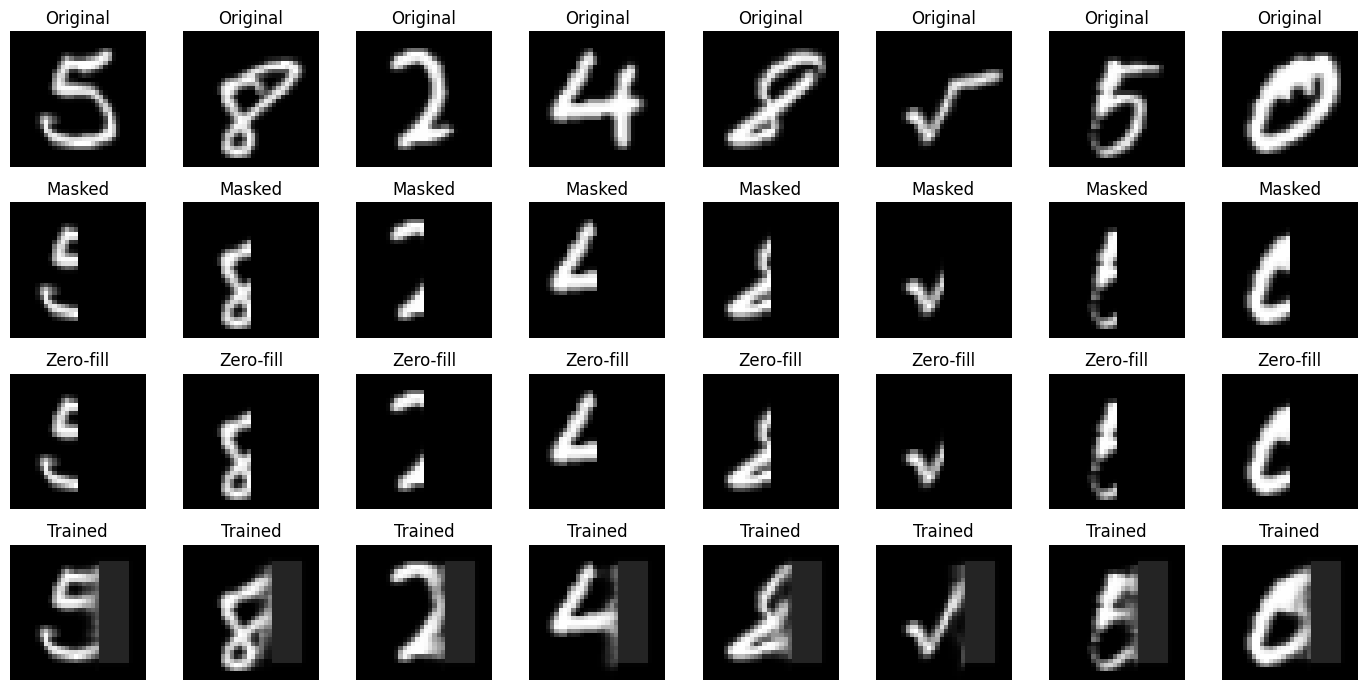

In [15]:
num_images = 8

x_zero_fill = physics.A_adjoint(y_test)

fig, axes = plt.subplots(4, num_images, figsize=(14, 7))

for i in range(num_images):
    axes[0, i].imshow(x_test[i, 0].detach().cpu(), cmap="gray")
    axes[0, i].axis("off")
    axes[0, i].set_title("Original")
    
    axes[1, i].imshow(y_test[i, 0].detach().cpu(), cmap="gray")
    axes[1, i].axis("off")
    axes[1, i].set_title("Masked")
    
    axes[2, i].imshow(x_zero_fill[i, 0].detach().cpu(), cmap="gray")
    axes[2, i].axis("off")
    axes[2, i].set_title("Zero-fill")
    
    axes[3, i].imshow(x_reconstructed[i, 0].detach().cpu(), cmap="gray")
    axes[3, i].axis("off")
    axes[3, i].set_title("Trained")

plt.tight_layout()
plt.show()

In [16]:
mse_zero_fill = torch.mean((x_test - x_zero_fill) ** 2).item()
mse_trained = torch.mean((x_test - x_reconstructed) ** 2).item()

print("MSE zero-filled baseline:", mse_zero_fill)
print("MSE trained reconstruction baseline:", mse_trained)

MSE zero-filled baseline: 0.055109210312366486
MSE trained reconstruction baseline: 0.02521209605038166


In [17]:
from pathlib import Path

project_root = Path("..") if Path.cwd().name == "notebooks" else Path(".")
checkpoint_dir = project_root / "checkpoints"
output_dir = project_root / "outputs"

checkpoint_dir.mkdir(exist_ok=True)
output_dir.mkdir(exist_ok=True)

model_path = checkpoint_dir / "trained_deepinv_mnist_inpainting_baseline.pth"

torch.save(model.state_dict(), model_path)

print("Saved model to:", model_path)

Saved model to: ..\checkpoints\trained_deepinv_mnist_inpainting_baseline.pth
